# Figure 2d — TetraSpeck bead precision, by excitation wavelength

**Makes up:** Figure 2d (position precision $\sigma_{xy}$ and colour precision $\sigma_\mathrm{colour}$
of single TetraSpeck beads against signal, with $a/\sqrt{N}+c$ fits, all three lasers pooled as
published). Also, for the reviewers: the same split by excitation laser (488, 561, 638 nm), with
per-laser fits and a comparison of the lasers where their signal ranges overlap.

**Data:** BioStudies `S-BIAD3210`, `2026_Multicolour_Paper/Ximea/TetraspeckBeads/Tetraspeck_<laser>_excitation/<power>_excitation/`:
0.1 µm TetraSpeck beads, 3 lasers × 7 powers (1–10 mW), 25 positions per acquisition (16 for
488 nm / 2 mW), each one TIFF of 200 frames (~430 MB) plus its MicroManager metadata. A stray
`1mW%20excitation` folder is not used.

**Method:** fit each position (`fit_SM_data`, 12 px ROI, PSF wavelength = the emission peak of the
TetraSpeck dye the laser excites) → AIM drift correction (10-frame segments, 20 nm intersection
distance, 60 nm search radius, as in the Methods) → HDBSCAN clustering of each acquisition's
localisations into beads (≥ 10 localisations) → per bead (seen in ≥ 50 of 200 frames), as in the SI
note *Calibrating Precision*:

* $\sigma_{xy}$ = mean of the standard deviations of x and y about the bead's own mean position;
* $\sigma_\mathrm{colour}$ = std / mean of the bead's relative pixel signal $A_X$ on pixel X (1, 2, 3);
* signal $N$ = the bead's mean **detected photoelectrons** per frame, $N = \sum_X f_X A_X$
  (SI Eq. S18): $A_X$ is the fitted amplitude on pixel type X, i.e. what that type would collect
  over the whole sensor, and $f_X$ the share of the sensor it covers ($\tfrac14, \tfrac12, \tfrac14$
  for the Bayer mosaic, from `Mask_Functions.pixel_fractions`). For colour, $N_X = f_X A_X$, the
  photoelectrons pixel type X detected.

**Changed from the published plot:**
1. The published axis was $A_1+A_2+A_3$, which overcounts the detected photoelectrons 2–4×; every
   point moves left by that factor relative to the literature ranges.
2. The published colour axis was $A_X$ with pixel 2 scaled by $\sqrt{2}$ (twice as many pixel-2
   pixels). $N_X = f_X A_X$ already counts that, so no scaling is applied.

The images are converted with the per-pixel gain, offset and relative QE maps in
`Camera_Calibrations/Ximea_Camera`. $N$ excludes background and is not corrected for the camera's
absolute QE, so it is not the number of photons reaching the sensor. The literature ranges are in
photons; they are drawn at the photoelectrons the Ximea would detect from them, i.e. × its effective QE
($\sum_p f_p \int \mathrm{PDF}\,\mathrm{QE}_p\,d\lambda$), averaged over ATTO 488 and ATTO 647N for organic
dyes and over EGFP, EYFP and mCherry for fluorescent proteins.

Quality cuts follow the Methods (χ²ν < 3, localisation error < 1 px, > 50 detected photoelectrons),
with two exceptions:
1. No cut on the colour error, so frames are not selected on the quantity being measured.
2. A PSF σ window of 75–250 nm instead of the single-dye 75–160 nm. The beads' fitted σ is
   ~145 nm at 561 nm and ~170 nm at 638 nm, so the single-dye window drops 40 % and 90 % of
   their frames.

The published plot's cleaning is kept: σ_xy 0.01–20 nm, σ_colour 0.5–50 %; the signal cap is
N < 10⁴ photoelectrons (the published < 2 × 10⁴ "photons" was ~0.7–0.9 × 10⁴ photoelectrons).
Shared code: `_multifov.py` (download / fit / drift / cluster) and `_beads.py` (settings, per-bead
precision, fits).

## FAST_MODE

`FAST_MODE = True` (default) uses one position (`Pos000_000`) per laser and power: 21 TIFFs,
~9 GB. Fitting takes ~2 min per position. The download from EBI usually takes far longer. Every
panel is made, from ~1/25 of the beads (a few to ~35 per acquisition), so the per-laser fits are
loose. `FAST_MODE = False` uses all 516 positions (~220 GB).

---
## 0 — Imports

In [1]:
import sys
import types
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# _biostudies_download.py, _multifov.py and _beads.py live beside this notebook.
sys.path.insert(0, str(Path.cwd().resolve()))
import _multifov as mf
import _beads as bd

from pyS3M import IOFunctions
from pyS3M import sCMOSFunctions
from pyS3M import SR_Functions
from pyS3M import SM_extractionfunctions
from pyS3M import PlottingBase
from pyS3M.DriftCorrectionFunctions import Drift_Correction_Functions

IO = IOFunctions.IO_Functions()
sCMOS = sCMOSFunctions.sCMOS_Functions()
SupRes_F = SR_Functions.SuperRes_Functions()   # Ximea defaults (69 nm pixels)
SM_E = SM_extractionfunctions.extract_SMs()
DC = Drift_Correction_Functions()
plotter = PlottingBase.PublicationPlotter(dark_background=False)

print("Python:", sys.version)

Python: 3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]


/home/u2473660/Documents/Code/pyS3M/src/ImportManager.py:152: UserWarning: Optional dependency missing: Could not import bokeh: No module named 'bokeh'
  warnings.warn(f"Optional dependency missing: {error_msg}", UserWarning)


---
## 1 — Configuration

In [2]:
FAST_MODE = False   # True: one position per laser and power (~9 GB). False: all 516 positions (~220 GB).
REFIT = False      # True: fit again even if fits with the same files and settings exist.
FAST_POSITION = "Pos000_000"
N_BOOT = 1000      # bootstrap resamples (over beads) for the 95 % intervals

REPO_ROOT = Path.cwd().resolve().parents[1]   # notebooks/figures -> repo root
CALIB_DIR = REPO_ROOT / "Camera_Calibrations" / "Ximea_Camera"
OUT_ROOT  = Path("/media/u2473660/JSBLeeLabBackup/Data/20261026_Tetraspeck")   # git-ignored (bare outputs/ rule)
FIG_DIR   = OUT_ROOT / ("fast" if FAST_MODE else "full")
# Point DATA_ROOT at a drive with room for the download. Each acquisition gets its own sub-folder,
# separately for each FAST_MODE setting: the fit reads every TIFF inside it.
DATA_ROOT = OUT_ROOT / ("data_fast" if FAST_MODE else "data_full")
FIG_DIR.mkdir(parents=True, exist_ok=True)
DATA_ROOT.mkdir(parents=True, exist_ok=True)

calib = dict(
    gain_map=IO.read_tiff(CALIB_DIR / "gain.tif"),
    offset_map=IO.read_tiff(CALIB_DIR / "offset.tif"),
    rqe=IO.read_tiff(CALIB_DIR / "rqe.tif"),
    read_noise=IO.read_tiff(CALIB_DIR / "readnoise.tif"),
    variance=IO.read_tiff(CALIB_DIR / "variance.tif"),
)

smoothing_function = types.SimpleNamespace()
smoothing_function.args = {"sigma": 1.5}
smoothing_function.extent = 1.5
smoothing_function.smoothing_function = sCMOS.gaussian_filter_stack
smoothing_function.data_arg = "image"

ACQUISITIONS = [(laser, power) for laser in bd.LASERS for power in bd.POWERS]

print(f"FAST_MODE  : {FAST_MODE}")
print(f"Data dir   : {DATA_ROOT.resolve()}")
print(f"Figures dir: {FIG_DIR.resolve()}")

FAST_MODE  : False
Data dir   : /media/u2473660/JSBLeeLabBackup/Data/20261026_Tetraspeck/data_full
Figures dir: /media/u2473660/JSBLeeLabBackup/Data/20261026_Tetraspeck/full


---
## 2 — Download, fit and drift-correct every acquisition

Per laser and power: download from BioStudies (with each position's metadata, which holds the camera
ROI the fit needs), fit each position, then AIM-correct its drift. Re-running is safe: complete
downloads are skipped, and fits are reused unless the files or settings change (or `REFIT = True`).

In [3]:
loc_files = {}
for laser, power in ACQUISITIONS:
    fit_params = dict(bd.FIT_PARAMS, peak_wavelength=bd.PEAK_UM[laser])
    print(f"\n=== {laser} nm, {power} (PSF wavelength {fit_params['peak_wavelength']} um)")
    loc_files[laser, power] = mf.prepare_acquisition(
        bd.remote_folder(laser, power), DATA_ROOT / laser / power, FAST_MODE, SupRes_F, calib,
        smoothing_function, IO, fit_params, drift_corrector=DC, drift_params=bd.DRIFT_PARAMS,
        position=FAST_POSITION if FAST_MODE else None, refit=REFIT,
    )

for (laser, power), files in loc_files.items():
    print(f"{laser} nm {power:>4}: {len(files)} position(s)")


=== 488 nm, 1mW (PSF wavelength 0.515 um)
2026_Multicolour_Paper/Ximea/TetraspeckBeads/Tetraspeck_488_excitation/1mW_excitation: 25 image file(s) + 25 metadata file(s); 50 already here
Reusing the fits in /media/u2473660/JSBLeeLabBackup/Data/20261026_Tetraspeck/data_full/488/1mW (same files and settings)

=== 488 nm, 2mW (PSF wavelength 0.515 um)
2026_Multicolour_Paper/Ximea/TetraspeckBeads/Tetraspeck_488_excitation/2mW_excitation: 16 image file(s) + 16 metadata file(s); 32 already here
Reusing the fits in /media/u2473660/JSBLeeLabBackup/Data/20261026_Tetraspeck/data_full/488/2mW (same files and settings)

=== 488 nm, 3mW (PSF wavelength 0.515 um)
2026_Multicolour_Paper/Ximea/TetraspeckBeads/Tetraspeck_488_excitation/3mW_excitation: 25 image file(s) + 25 metadata file(s); 50 already here
Reusing the fits in /media/u2473660/JSBLeeLabBackup/Data/20261026_Tetraspeck/data_full/488/3mW (same files and settings)

=== 488 nm, 4mW (PSF wavelength 0.515 um)
2026_Multicolour_Paper/Ximea/Tetrasp

---
## 3 — Beads and their precision

Each acquisition is clustered on its own, then reduced to one row per bead (`_beads.bead_precision`).
`sigma_xy_cm` is a check, not the published quantity (see §7). It also removes the motion each frame
shares with the other beads in the same field.

In [4]:
tables = []
for (laser, power), files in loc_files.items():
    _, sf_db = mf.cluster_sample(SM_E, files, DATA_ROOT / laser / power, f"{laser}_{power}",
                                 bd.CLUSTER_PARAMS)
    tables.append(bd.bead_precision(sf_db).assign(laser=laser, power=power))
beads = pd.concat(tables, ignore_index=True)
beads.to_csv(FIG_DIR / "bead_precision.csv", index=False)

loc = bd.clean_loc(beads)
colour = bd.clean_colour(bd.colour_long(beads))

summary = beads.groupby(["laser", "power"], sort=False).agg(
    beads=("n", "size"), median_frames=("n", "median"), median_pe=("pe", "median"))
summary["in_loc_plot"] = loc.groupby(["laser", "power"], sort=False).size()
print(f"{len(beads):,} beads seen in >= {bd.MIN_FRAMES} frames; {len(loc):,} in the sigma_xy plot, "
      f"{len(colour):,} bead-pixel pairs in the colour plot")
summary.round(0)

4,024 beads seen in >= 50 frames; 3,031 in the sigma_xy plot, 10,543 bead-pixel pairs in the colour plot


beads  median_frames  median_pe  in_loc_plot
laser power                                              
488   1mW      195          173.0      300.0        159.0
      2mW      145          197.0     2920.0        143.0
      3mW      126          198.0     4400.0         67.0
      4mW       67          197.0     4050.0          9.0
      6mW       48          120.0     1777.0          3.0
      8mW       62           85.0      154.0          NaN
      10mW      96           94.0      163.0          1.0
561   1mW      246          168.0      380.0        190.0
      2mW      265          179.0     1157.0        218.0
      3mW      259          191.0     2745.0        258.0
      4mW      221          192.0     3549.0        215.0
      6mW      198          192.0     6176.0        155.0
      8mW       99          114.0      225.0         20.0
      10mW     110           90.0      185.0          6.0
638   1mW      244          170.0     1006.0        196.0
      2mW      237          173.0     1622.0        215.0
      3mW      280          181.0     2479.0        267.0
      4mW      264          180.0     3321.0        251.0
      6mW      284          182.0     4376.0        245.0
      8mW      282          196.0     5300.0        217.0
      10mW     296          195.0     5042.0        196.0

---
## 4 — Figure 2d, as published: all lasers pooled

Top: σ_xy. Bottom: σ_colour, all three pixels, against the photoelectrons detected on that pixel type.
Solid lines: $a/\sqrt{N}+c$ fits (`curve_fit`, `sigma = 1/N`, as published). Dashed lines: 25th–75th
percentiles of the literature photons per localisation of fluorescent proteins (black) and organic
dyes (green), converted to the photoelectrons the Ximea would detect (× its effective QE, averaged over
EGFP / EYFP / mCherry and over ATTO 488 / ATTO 647N).

/tmp/ipykernel_2301222/1989512057.py:30: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


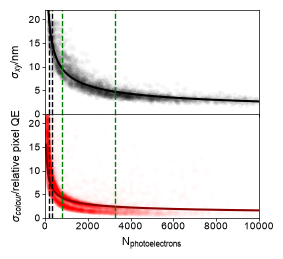

Literature 25th-75th percentiles, photons -> detected photoelectrons on the Ximea:
  fluorescent proteins [  550.  1000.] x QE 0.323 = [ 177.  323.]
  organic dyes         [  2796.5  11706. ] x QE 0.280 = [  783.  3279.]


,n_beads,a,a_lo,a_hi,c,c_lo,c_hi,at_1e3,at_5e3
sigma_xy / nm,3031.0,274.88,268.21,280.95,-0.12,-0.22,-0.01,8.57,3.77
sigma_colour / %,10543.0,106.13,92.92,118.94,0.50,0.19,0.82,3.86,2.00


In [5]:
N_MIN = 50   # the quality cut
N_GRID = np.linspace(N_MIN, bd.MAX_PE, 500)


def fit_table(groups):
    """groups: {name: (N, sigma)} -> a, c with 95 % bootstrap intervals, and sigma at 1e3 / 5e3."""
    rows = {}
    for name, (x, y) in groups.items():
        p, ci = bd.fit_power_law(x, y, n_boot=N_BOOT)
        rows[name] = {"n_beads": len(x), "a": p[0], "a_lo": ci[0, 0], "a_hi": ci[0, 1],
                      "c": p[1], "c_lo": ci[1, 0], "c_hi": ci[1, 1],
                      "at_1e3": bd.power_law(1e3, *p), "at_5e3": bd.power_law(5e3, *p)}
    return pd.DataFrame(rows).T


FP_PE, FP_QE = bd.literature_pe(bd.FLUORESCENT_PROTEINS, bd.FLUORESCENT_PROTEIN_REFS)
DYE_PE, DYE_QE = bd.literature_pe(bd.ORGANIC_DYES, bd.ORGANIC_DYE_REFS)


def range_lines(ax):
    for values, c in [(FP_PE, "black"), (DYE_PE, "green")]:
        for v in values:
            ax.axvline(v, lw=1, color=c, ls="--")


pooled_fits = fit_table({"sigma_xy / nm": (loc["pe"], loc["sigma_xy"]),
                         "sigma_colour / %": (colour["pe_px"], colour["prec_pct"])})

fig, (ax1, ax2) = plotter.one_column_plot(npanels=2, ratios=[1, 1], height=2.46, width=2.6779528)
fig.tight_layout()
fig.subplots_adjust(hspace=0)
ax1.scatter(loc["pe"], loc["sigma_xy"], s=50, lw=0, color="k", alpha=0.03, marker=".", rasterized=True)
ax1.plot(N_GRID, bd.power_law(N_GRID, *pooled_fits.loc["sigma_xy / nm", ["a", "c"]]), color="k", lw=1.5)
ax2.scatter(colour["pe_px"], colour["prec_pct"], s=50, lw=0, color="r", alpha=0.01, marker=".", rasterized=True)
ax2.plot(N_GRID, bd.power_law(N_GRID, *pooled_fits.loc["sigma_colour / %", ["a", "c"]]), color="darkred", lw=1.5)
for ax in (ax1, ax2):
    range_lines(ax)
    ax.set_xlim(0, bd.MAX_PE)
    ax.set_ylim(0, 22)
ax1.set_xticklabels([])
ax1.set_ylabel(r"$\sigma_{xy}$/nm")
ax2.set_ylabel(r"$\sigma_{colour}$/relative pixel QE")
ax2.set_xlabel(r"N$_{\mathrm{photoelectrons}}$")
plt.savefig(FIG_DIR / "Precision_Beads_all_excitation_photoelectrons_powerLawFitsLinear.svg", dpi=600, format="svg", bbox_inches="tight")
plt.show()

print(f"Literature 25th-75th percentiles, photons -> detected photoelectrons on the Ximea:\n"
      f"  fluorescent proteins {bd.quartiles(bd.FLUORESCENT_PROTEINS)} x QE {FP_QE:.3f} = {FP_PE.round(0)}\n"
      f"  organic dyes         {bd.quartiles(bd.ORGANIC_DYES)} x QE {DYE_QE:.3f} = {DYE_PE.round(0)}")
pooled_fits.astype(float).round(2)

---
## 5 — Do the lasers agree where their signal ranges overlap?

Each laser's beads are binned on N (log-spaced bins). For each bin with ≥ 5 beads, the plot shows the
median and its 95 % bootstrap interval. Lasers agree where their intervals overlap. Colour precision
is binned per pixel, on the signal on that pixel. The table lists the bins where at least two lasers
have ≥ 5 beads.

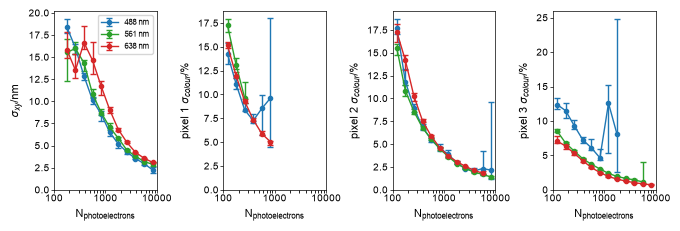

In [14]:
EDGES = np.geomspace(100, bd.MAX_PE, 13)
MIN_PER_BIN = 3 if FAST_MODE else 5


def log_x(ax):
    ax.set_xscale("log")
    ax.set_xlim(EDGES[0], EDGES[-1])
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}"))
    ax.xaxis.set_minor_formatter(mticker.NullFormatter())


fig, axs = plotter.two_column_plot(nrows=1, ncols=4, height=2.2)
binned = {}
for laser in bd.LASERS:
    d = loc[loc["laser"] == laser]
    binned["sigma_xy", laser] = bd.binned_medians(d["pe"], d["sigma_xy"], EDGES, MIN_PER_BIN, N_BOOT)
    for ch in bd.CHANNELS:
        e = colour[(colour["laser"] == laser) & (colour["channel"] == ch)]
        binned[f"colour_{ch}", laser] = bd.binned_medians(e["pe_px"], e["prec_pct"], EDGES, MIN_PER_BIN, N_BOOT)

panels = [("sigma_xy", r"$\sigma_{xy}$/nm"), ("colour_B", r"pixel 1 $\sigma_{colour}$/relative pixel QE"),
          ("colour_G", r"pixel 2 $\sigma_{colour}$/relative pixel QE"), ("colour_R", r"pixel 3 $\sigma_{colour}$/relative pixel QE")]
for ax, (key, ylabel) in zip(axs, panels):
    for laser in bd.LASERS:
        b = binned[key, laser]
        ax.errorbar(b["pe"], b["median"], yerr=[b["median"] - b["lo"], b["hi"] - b["median"]],
                    color=bd.LASER_COLOURS[laser], marker="o", ms=3, lw=1, capsize=2, label=f"{laser} nm")
    log_x(ax)
    ax.set_ylim(bottom=0)
    ax.set_xlabel(r"N$_{\mathrm{photoelectrons}}$")
    ax.set_ylabel(ylabel)
axs[0].legend(fontsize=6)
plt.savefig(FIG_DIR / "Precision_Beads_by_excitation_binned.svg", dpi=600, format="svg", bbox_inches="tight")
plt.show()

rows = []
for key, _ in panels:
    wide = pd.concat({l: binned[key, l].set_index("pe")[["n", "median", "lo", "hi"]] for l in bd.LASERS}, axis=1)
    shared = wide.xs("median", axis=1, level=1).notna().sum(axis=1) >= 2
    rows.append(wide[shared].assign(quantity=key))
overlap = pd.concat(rows).reset_index().set_index(["quantity", "pe"])
overlap.to_csv(FIG_DIR / "overlap_binned_medians.csv")

---
## 6 — Precision at 1,000 photons reaching the detector

For quoting in the abstract. A count of photons reaching the camera does depend on our camera,
unlike photoelectrons. For each laser, 1,000 photons from the beads under that laser (after the
emission filters) give $N_\mathrm{pe} = 1000 \sum_X f_X q_X$ detected photoelectrons, of which
$1000\,f_X q_X$ are on pixel type X. Here $q_X = \int \mathrm{PDF}(\lambda)\,\mathrm{QE}_X(\lambda)\,d\lambda$, where
PDF is the beads' measured emission at that laser after the bead emission filters
(`_beads.bead_effective_qe`).

- σ_xy is read from that laser's fit (§5) at $N_\mathrm{pe}$, and from the pooled fit (§4).
- σ_colour of each pixel type is read from that laser's colour fit at its $1000\,f_X q_X$.
- The intervals are 95 % bootstrap intervals over beads.
- The table also counts the beads within 0.5–2× N_pe. With few such beads, the value is an
  extrapolation of the fit and should not be quoted.

The spectra are the beads' emission measured at each laser (spectrofluorometer, instrument-corrected,
2026-10-29; `tetraspeck_emission_spectra.csv`. Each
laser excites every TetraSpeck dye it can, so they include, e.g., the dark-red emission under 488 and
561 nm excitation. Before, each laser used one database dye (the FluoSpheres dye TetraSpeck is made
from, shifted to the manufacturer emission peak); the last table compares the two. Only 561 nm changes
much: its measured emission is broader than the orange database spectrum and puts less of it on the
green pixels.

In [9]:
PHOTONS = 1000
rows, xy_boot = {}, {}
for laser in bd.LASERS:
    qe, q = bd.bead_effective_qe(laser)
    n_pe = PHOTONS * qe
    d = loc[loc["laser"] == laser]
    dc = colour[colour["laser"] == laser]
    row = {"effective QE": qe, "N_pe": n_pe,
           # beads near N_pe: the value is read from data, not extrapolated, only if there are some
           "beads within 0.5-2 x N_pe": int(d["pe"].between(n_pe / 2, 2 * n_pe).sum()),
           "dimmest bead / pe": d["pe"].min()}
    (row["sigma_xy / nm"], row["sigma_xy lo"], row["sigma_xy hi"],
     xy_boot[f"{laser} nm"]) = bd.power_law_at(d["pe"], d["sigma_xy"], n_pe, N_BOOT, return_samples=True)
    row["sigma_xy pooled fit / nm"] = bd.power_law(n_pe, *pooled_fits.loc["sigma_xy / nm", ["a", "c"]])
    for ch in bd.CHANNELS:
        n_x = PHOTONS * bd.PIXEL_FRACTIONS[ch] * q[ch]
        row[f"N_pe pixel {ch}"] = n_x
        row[f"sigma_colour {ch} / %"], row[f"{ch} lo"], row[f"{ch} hi"] = bd.power_law_at(
            dc["pe_px"], dc["prec_pct"], n_x, N_BOOT)
    rows[f"{laser} nm"] = row
at_1000 = pd.DataFrame(rows).T
at_1000.to_csv(FIG_DIR / "precision_at_1000_photons.csv")

print(f"At {PHOTONS:,} photons reaching the detector:")
for laser, r in at_1000.iterrows():
    print(f"  {laser}: {r['N_pe']:.0f} pe -> sigma_xy {r['sigma_xy / nm']:.1f} nm "
          f"(95 % {r['sigma_xy lo']:.1f}-{r['sigma_xy hi']:.1f}); sigma_colour "
          + ", ".join(f"pixel {i + 1} {r[f'sigma_colour {ch} / %']:.1f} %" for i, ch in enumerate(bd.CHANNELS)))
print(f"Largest upper bound on sigma_xy across lasers: {at_1000['sigma_xy hi'].max():.1f} nm")
if (at_1000["beads within 0.5-2 x N_pe"] < 10).any():
    print("WARNING: fewer than 10 beads near N_pe for some lasers; their values are extrapolated from the fit.")
at_1000.astype(float).round(2)

At 1,000 photons reaching the detector:
  488 nm: 363 pe -> sigma_xy 13.1 nm (95 % 12.6-13.5); sigma_colour pixel 1 26.2 %, pixel 2 10.4 %, pixel 3 31.4 %
  561 nm: 298 pe -> sigma_xy 14.1 nm (95 % 13.7-14.6); sigma_colour pixel 1 28.8 %, pixel 2 6.6 %, pixel 3 7.3 %
  638 nm: 204 pe -> sigma_xy 21.4 nm (95 % 20.9-21.9); sigma_colour pixel 1 42.4 %, pixel 2 15.4 %, pixel 3 12.4 %
Largest upper bound on sigma_xy across lasers: 21.9 nm


,effective QE,N_pe,beads within 0.5-2 x N_pe,dimmest bead / pe,sigma_xy / nm,sigma_xy lo,sigma_xy hi,sigma_xy pooled fit / nm,N_pe pixel B,sigma_colour B / %,B lo,B hi,N_pe pixel G,sigma_colour G / %,G lo,G hi,N_pe pixel R,sigma_colour R / %,R lo,R hi
488 nm,0.36,362.88,151.0,162.24,13.08,12.64,13.49,14.31,36.34,26.24,19.53,32.72,301.89,10.41,8.79,11.95,24.65,31.43,23.08,39.50
561 nm,0.30,297.70,192.0,126.14,14.11,13.66,14.60,15.81,6.26,28.76,21.61,34.69,163.14,6.60,5.60,7.43,128.30,7.29,6.09,8.27
638 nm,0.20,203.58,37.0,122.91,21.40,20.89,21.88,19.15,10.71,42.43,40.88,43.96,76.85,15.37,14.87,15.86,116.03,12.37,11.98,12.75


### Mean over the three lasers, weighted by beads (quoted in the main text)

The main text quotes one number: the mean of the three per-laser σ_xy at 1,000 photons, each weighted
by the number of beads within 0.5–2× that laser's N_pe, i.e. the beads that set its value (a laser
whose value is mostly extrapolated counts for less). Its 95 % interval comes from the same weighted
average of the three lasers' bootstrap values, draw by draw (the lasers are independent bead sets, so
each draw is one resample of every laser). For comparison, the output also gives the unweighted mean
and the mean weighted by all beads in each laser's fit (§5).

In [10]:
n_beads = loc.groupby("laser").size().reindex(bd.LASERS).to_numpy(float)
n_near = at_1000["beads within 0.5-2 x N_pe"].astype(float).to_numpy()
xy = at_1000["sigma_xy / nm"].astype(float).to_numpy()
boot = np.vstack(list(xy_boot.values()))


def weighted(w):
    """Weighted mean of the per-laser sigma_xy, with a 95 % interval from the bootstrap draws."""
    w = np.asarray(w, float) / np.sum(w)
    return (w @ xy, *np.nanpercentile(w @ boot, [2.5, 97.5]))


mean_xy, mean_lo, mean_hi = weighted(n_near)
means = pd.DataFrame({name: dict(zip(["sigma_xy / nm", "sigma_xy lo", "sigma_xy hi"], weighted(w)))
                      for name, w in [("mean weighted by beads within 0.5-2 x N_pe", n_near),
                                      ("mean weighted by beads in fit", n_beads),
                                      ("unweighted mean", np.ones(3))]}).T
means["sigma_xy pooled fit / nm"] = [np.average(at_1000["sigma_xy pooled fit / nm"].astype(float), weights=w)
                                     for w in (n_near, n_beads, np.ones(3))]
pd.concat([at_1000.assign(**{"beads in fit": n_beads}), means]).to_csv(FIG_DIR / "precision_at_1000_photons.csv")

print(f"sigma_xy at {PHOTONS:,} photons reaching the detector:")
for (laser, r), n in zip(at_1000.iterrows(), n_beads):
    print(f"  {laser}: {r['sigma_xy / nm']:.2f} nm (95 % {r['sigma_xy lo']:.2f}-{r['sigma_xy hi']:.2f}), "
          f"{n:.0f} beads in fit, {r['beads within 0.5-2 x N_pe']:.0f} within 0.5-2 x N_pe")
for name, r in means.iterrows():
    print(f"  {name}: {r['sigma_xy / nm']:.2f} nm (95 % {r['sigma_xy lo']:.2f}-{r['sigma_xy hi']:.2f})")


sigma_xy at 1,000 photons reaching the detector:
  488 nm: 13.08 nm (95 % 12.64-13.49), 382 beads in fit, 151 within 0.5-2 x N_pe
  561 nm: 14.11 nm (95 % 13.66-14.60), 1062 beads in fit, 192 within 0.5-2 x N_pe
  638 nm: 21.40 nm (95 % 20.89-21.88), 1587 beads in fit, 37 within 0.5-2 x N_pe
  mean weighted by beads within 0.5-2 x N_pe: 14.41 nm (95 % 14.12-14.70)
  mean weighted by beads in fit: 17.80 nm (95 % 17.48-18.10)
  unweighted mean: 16.20 nm (95 % 15.93-16.45)


In [11]:
# Effective QE from the measured bead spectra (used) against the database spectra used before
rows = {}
for laser in bd.LASERS:
    qe_measured = bd.bead_effective_qe(laser)[0]
    qe_database = bd.bead_effective_qe(laser, spectrum=bd.TETRASPECK_SPECTRA[laser])[0]
    rows[f"{laser} nm"] = {"effective QE, measured (used)": qe_measured, "effective QE, database": qe_database,
                           "change / %": 100 * (qe_measured / qe_database - 1),
                           "N_pe at 1,000 photons, measured": PHOTONS * qe_measured,
                           "N_pe at 1,000 photons, database": PHOTONS * qe_database}
pd.DataFrame(rows).T.round(3)

,"effective QE, measured (used)","effective QE, database",change / %,"N_pe at 1,000 photons, measured","N_pe at 1,000 photons, database"
488 nm,0.363,0.366,-0.818,362.882,365.876
561 nm,0.298,0.334,-10.874,297.704,334.027
638 nm,0.204,0.205,-0.613,203.583,204.838


---
## 7 — A fair comparison with Huang et al. (2013)

The main text compares our precision at 1,000 photons with an sCMOS camera (ORCA-Flash 4.0) from
Huang *et al.*, *Nat. Methods* **10**, 653 (2013), Fig. 1d. There the signal is photons *incident on
the camera* (their simulation includes a 75 % QE). The
precision also depends on the background, which their Fig. 1d gives as 1, 5 and 20 *detected* photons
per 103 nm pixel (≈ 8.0, 9.0 and 11.4 nm at 1,000 photons, digitised: `_beads.HUANG_SIGMA_AT_1000`).

To put our background on their scale, for each laser:

1. take the median background per pixel (detected photoelectrons, $\sum_p f_p b_p$) of the beads
   within 0.5–2× $N_\mathrm{pe}$, i.e. the beads that set σ_xy at 1,000 photons;
2. divide by the effective QE to get photons per pixel reaching the detector (this assumes the
   background has the bead's spectrum after the filters);
3. scale to their pixel area, × (103 / 69)², and multiply by their 75 % QE.

Their precision at that background (interpolated in log bg) is the fair comparison. Their values are averaged over the lasers with the same bead weights as ours (§8).

In [15]:
huang_rows = {}
for laser in bd.LASERS:
    r = at_1000.loc[f"{laser} nm"]
    d = loc[loc["laser"] == laser]
    near = d[d["pe"].between(r["N_pe"] / 2, 2 * r["N_pe"])]
    bg_pe = near["bg_pe"].median()
    bg_photons = bg_pe / r["effective QE"]
    bg_huang = bg_photons * (bd.HUANG_PIXEL_NM / bd.PIXEL_NM) ** 2 * bd.HUANG_QE
    huang_rows[f"{laser} nm"] = {
        "beads": len(near), "bg / pe per pixel": bg_pe, "bg / photons per pixel": bg_photons,
        "bg / Huang detected photons per 103 nm pixel": bg_huang,
        "Huang sigma at 1,000 photons / nm": bd.huang_sigma_at_1000(bg_huang),
        "our sigma_xy / nm": r["sigma_xy / nm"]}
huang = pd.DataFrame(huang_rows).T.astype(float)
huang.loc["mean, weighted by beads near N_pe"] = np.average(huang.to_numpy(), axis=0, weights=n_near)
huang.loc["mean, weighted by beads near N_pe", "our sigma_xy / nm"] = mean_xy
huang["ours / Huang - 1 / %"] = 100 * (huang["our sigma_xy / nm"] / huang["Huang sigma at 1,000 photons / nm"] - 1)
huang.to_csv(FIG_DIR / "huang_comparison.csv")

outside = huang["bg / Huang detected photons per 103 nm pixel"].iloc[:3]
if (outside < bd.HUANG_BG[0]).any():
    print("NOTE: a background is below Huang et al.'s lowest (1 photon/pixel); their bg = 1 value is used, "
          "but at our lower background theirs would be better still, so the % difference is a lower bound.")
if (outside > bd.HUANG_BG[-1]).any():
    print("WARNING: a background is above Huang et al.'s highest (20 photons/pixel); their value is clipped.")
m = huang.loc["mean, weighted by beads near N_pe"]
print(f"Our background, on Huang et al.'s scale: "
      + ", ".join(f"{l} {v:.1f}" for l, v in outside.items()) + " detected photons per 103 nm pixel")
print(f"Huang et al. at those backgrounds, 1,000 photons: {m['Huang sigma at 1,000 photons / nm']:.1f} nm (bead-weighted mean)")
print(f"Ours: {mean_xy:.1f} nm (95 % {mean_lo:.1f}-{mean_hi:.1f}) -> {m['ours / Huang - 1 / %']:.0f} % higher")
print(f"(vs their lowest background, {bd.HUANG_SIGMA_AT_1000[0]:.1f} nm: {100 * (mean_xy / bd.HUANG_SIGMA_AT_1000[0] - 1):.0f} % higher)")
huang.round(2)

NOTE: a background is below Huang et al.'s lowest (1 photon/pixel); their bg = 1 value is used, but at our lower background theirs would be better still, so the % difference is a lower bound.
Our background, on Huang et al.'s scale: 488 nm 0.5, 561 nm 0.8, 638 nm 3.0 detected photons per 103 nm pixel
Huang et al. at those backgrounds, 1,000 photons: 8.1 nm (bead-weighted mean)
Ours: 14.4 nm (95 % 14.1-14.7) -> 79 % higher
(vs their lowest background, 8.0 nm: 80 % higher)


,beads,bg / pe per pixel,bg / photons per pixel,bg / Huang detected photons per 103 nm pixel,"Huang sigma at 1,000 photons / nm",our sigma_xy / nm,ours / Huang - 1 / %
488 nm,151.00,0.12,0.33,0.55,8.00,13.08,63.52
561 nm,192.00,0.15,0.50,0.83,8.00,14.11,76.44
638 nm,37.00,0.36,1.77,2.96,8.67,21.40,146.77
"mean, weighted by beads near N_pe",160.62,0.16,0.55,0.93,8.07,14.41,78.71
